# 01 · 探索性数据分析（EDA）

**业务问题**：知识区视频的传播效果如何分布？哪些领域、UP层级和内容形态表现更好？

**数据**：`outputs/modeling_dataset.csv`（4129 条 × 全部特征，清洗与特征工程由步骤1-5生成）。
**分析方法**：描述统计、分布检验、分组对比。

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if (ROOT / 'src').exists():
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import paths

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid')

df = pd.read_csv(paths.MODELING_CSV, encoding='utf-8-sig', low_memory=False)
print('建模数据集：', df.shape)
df.head(3)

建模数据集： (4129, 133)


,uid,up_name,fans,level,domain,bvid,title,cover_url,pubdate,duration,...,synergy_rule_reason,type_high_synergy,type_complementary_explanation,type_redundant_reinforcement,type_curiosity_contrast,type_emotional_conflict,type_low_relatedness,cover_has_chart_or_formula,cover_is_slide_or_screenshot,cover_acgn_style
0,946974,影视飓风,16127991,1,科学科普,BV1DbiMBwEry,和魔术师刘谦一起拉片魔术电影,http://i1.hdslb.com/bfs/archive/6c1a4f23aa4e24...,2025-12-31 17:00:00,809,...,"Pdef-兜底→低关联: fit=0.271(<median), 无其他强信号",0,0,0,0,0,1,NaN,NaN,NaN
1,946974,影视飓风,16127991,1,财经商业,BV1cAvaB5ENH,千万粉丝博主潘天鸿：透过小屏幕，带你探索大世界,http://i0.hdslb.com/bfs/archive/c2a5a42a2955b1...,2025-12-30 12:07:43,1372,...,"P6-好奇对比: title_has_curiosity=1, fit=0.487(中等),...",0,0,0,1,0,0,NaN,NaN,NaN
2,946974,影视飓风,16127991,1,职场教育,BV1vhBBBFEzQ,带着100万...我们去了论文代写聚集地,http://i0.hdslb.com/bfs/archive/711cec349e0735...,2025-12-27 11:01:41,2443,...,"Pdef-兜底→低关联: fit=0.319(<median), 无其他强信号",0,0,0,0,0,1,NaN,NaN,NaN


In [2]:
# 数据质量速览
print('唯一视频数:', df['bvid'].nunique(), '| UP主数:', df['uid'].nunique())
print('缺失值总数:', int(df.isna().sum().sum()))
print('\n核心数值字段描述:')
df[['view','like','coin','favorite','share','fans','duration']].describe(percentiles=[.5,.9]).round(0)

唯一视频数: 4129 | UP主数: 68
缺失值总数: 23907

核心数值字段描述:


,view,like,coin,favorite,share,fans,duration
count,4129.0,4129.0,4129.0,4129.0,4129.0,4129.0,4129.0
mean,738331.0,30212.0,8849.0,8904.0,1458.0,1226766.0,845.0
std,1771672.0,79301.0,40338.0,26811.0,7265.0,2799711.0,933.0
min,149.0,2.0,0.0,1.0,0.0,14240.0,7.0
50%,53061.0,1803.0,201.0,856.0,58.0,354287.0,755.0
90%,2269271.0,97990.0,15958.0,20678.0,2861.0,3330440.0,1697.0
max,30335606.0,1360128.0,899355.0,531974.0,272614.0,16127991.0,36944.0


C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: UserWarning: Glyph 25773 (\N{CJK UNIFIED IDEOGRAPH-64AD}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: UserWarning: Glyph 25918 (\N{CJK UNIFIED IDEOGRAPH-653E}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\1241448535.py:5: Use

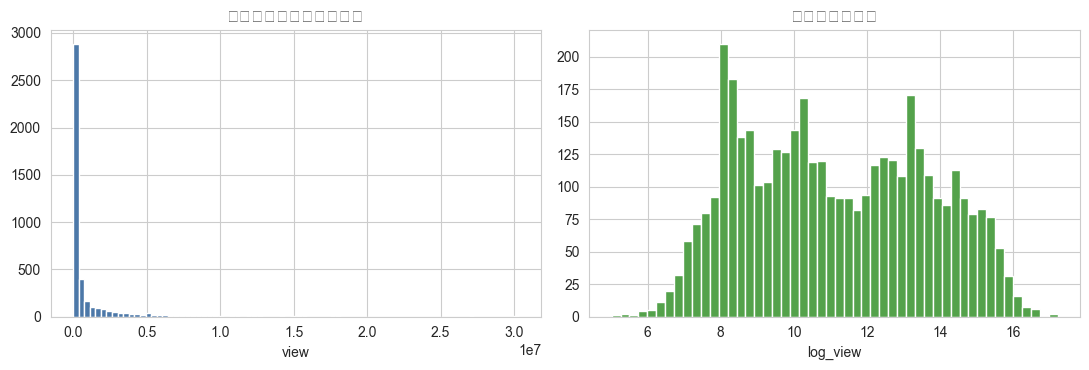

偏度: 原始=5.30, 对数=0.12


In [3]:
# 播放量高度右偏（少数爆款拉高均值），因此研究使用对数化指标
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df['view'], bins=80, color='#4C78A8'); axes[0].set_title('播放量原始分布（右偏）'); axes[0].set_xlabel('view')
axes[1].hist(df['log_view'], bins=50, color='#54A24B'); axes[1].set_title('播放量对数分布'); axes[1].set_xlabel('log_view')
plt.tight_layout(); plt.show()
print('偏度: 原始=%.2f, 对数=%.2f' % (df['view'].skew(), df['log_view'].skew()))

C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:11: UserWarning: Glyph 31038 (\N{CJK UNIFIED IDEOGRAPH-793E}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:11: UserWarning: Glyph 31185 (\N{CJK UNIFIED IDEOGRAPH-79D1}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:11: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:11: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:11: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\3648204495.py:1

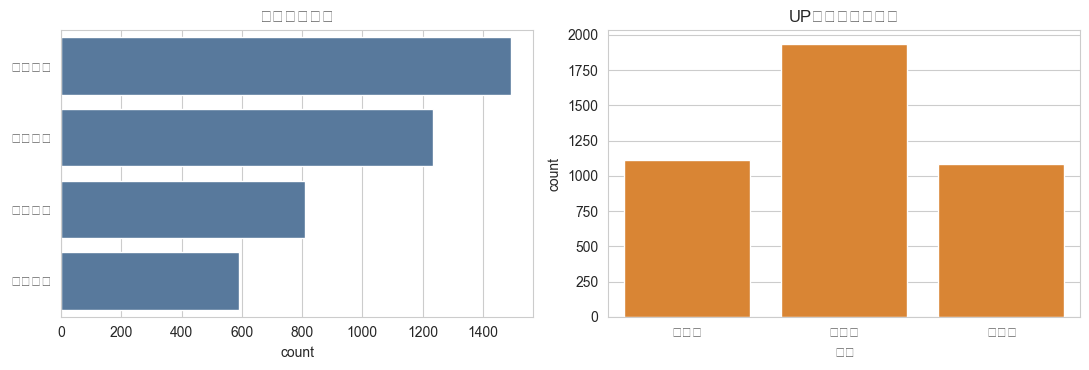

In [4]:
# 样本结构：领域 × UP层级
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = df['domain'].value_counts().index
sns.countplot(data=df, y='domain', order=order, ax=axes[0], color='#4C78A8')
axes[0].set_title('各领域视频数'); axes[0].set_ylabel('')
level_map = {1:'高层级', 0:'中层级', -1:'低层级'}
tmp = df['level'].map(level_map)
sns.countplot(data=tmp.to_frame('层级'), x='层级', ax=axes[1], color='#F58518',
              order=['低层级','中层级','高层级'])
axes[1].set_title('UP主粉丝层级分布')
plt.tight_layout(); plt.show()

In [5]:
# 互动漏斗：播放 -> 点赞 -> 投币 -> 收藏 -> 分享 -> 弹幕 -> 评论
stages = [('播放','view'),('点赞','like'),('投币','coin'),('收藏','favorite'),
          ('分享','share'),('弹幕','danmaku'),('评论','reply')]
tot = df[[c for _,c in stages]].sum()
for i,(n,c) in enumerate(stages):
    if i==0:
        print(f'{n:>4}: {tot[c]:>12,.0f}  转化率 100%')
    else:
        prev = stages[i-1][1]
        print(f'{n:>4}: {tot[c]:>12,.0f}  相对上一环 {tot[c]/tot[prev]*100:6.2f}%')

  播放: 3,048,570,551  转化率 100%
  点赞:  124,746,601  相对上一环   4.09%
  投币:   36,536,904  相对上一环  29.29%
  收藏:   36,766,235  相对上一环 100.63%
  分享:    6,019,678  相对上一环  16.37%
  弹幕:    9,792,279  相对上一环 162.67%
  评论:    4,167,269  相对上一环  42.56%


,点赞率,投币率,收藏率,分享率,评论率
domain,,,,,
财经商业,5.00,1.81,1.37,0.32,0.57
职场教育,5.29,1.22,3.43,0.34,0.29
社科人文,4.41,0.85,1.77,0.26,0.31
科学科普,3.61,0.50,1.91,0.22,0.17


C:\Users\19357\AppData\Local\Temp\ipykernel_24388\2860693318.py:7: UserWarning: Glyph 31038 (\N{CJK UNIFIED IDEOGRAPH-793E}) missing from font(s) Arial.
  plt.xticks(rotation=0); plt.ylabel('%'); plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\2860693318.py:7: UserWarning: Glyph 31185 (\N{CJK UNIFIED IDEOGRAPH-79D1}) missing from font(s) Arial.
  plt.xticks(rotation=0); plt.ylabel('%'); plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\2860693318.py:7: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  plt.xticks(rotation=0); plt.ylabel('%'); plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\2860693318.py:7: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) Arial.
  plt.xticks(rotation=0); plt.ylabel('%'); plt.tight_layout(); plt.show()
C:\Users\19357\AppData\Local\Temp\ipykernel_24388\2860693318.py:7: UserWarning: Glyph 23398 

C:\Users\19357\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 31038 (\N{CJK UNIFIED IDEOGRAPH-793E}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19357\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 31185 (\N{CJK UNIFIED IDEOGRAPH-79D1}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19357\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19357\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19357\AppData\Local\Programs\Python\Python313\Lib\site-pack

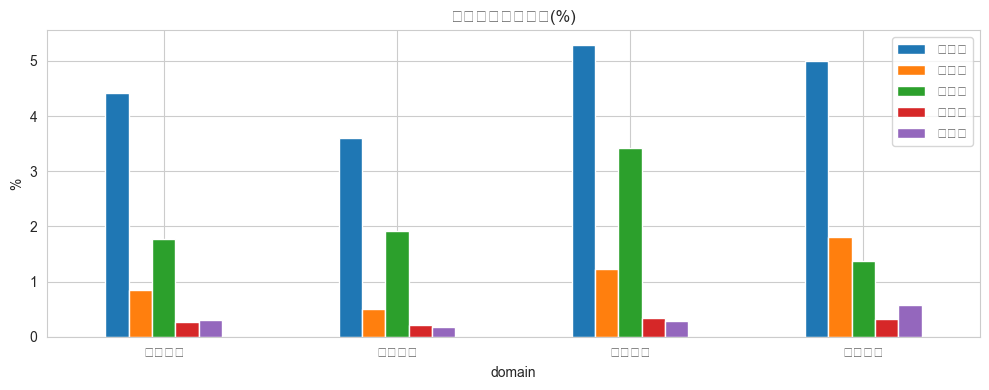

In [6]:
# 各领域互动率（投币/收藏是B站知识内容的高价值认可指标）
rate_cols = ['like_rate','coin_rate','favorite_rate','share_rate','comment_rate']
g = df.groupby('domain')[rate_cols].mean().mul(100).round(2)
g.columns = ['点赞率','投币率','收藏率','分享率','评论率']
display(g.sort_values('投币率', ascending=False))
g.plot(kind='bar', figsize=(10,4), title='各领域平均互动率(%)')
plt.xticks(rotation=0); plt.ylabel('%'); plt.tight_layout(); plt.show()

In [7]:
# 高/低传播组（中位数分组）标题与双模态特征对比
df['high_group'] = df['log_view'] >= df['log_view'].median()
cmp_cols = ['title_has_number','title_char_len','curiosity_marker_count',
            'image_title_fit','title_cover_text_overlap','visual_complexity']
g = df.groupby('high_group')[cmp_cols].mean().round(3)
g.index = ['低传播组','高传播组']
display(g)
print('\nMann-Whitney U 检验示例（图文语义匹配度）：')
from scipy import stats
u,p = stats.mannwhitneyu(df.loc[df.high_group,'image_title_fit'],
                         df.loc[~df.high_group,'image_title_fit'], alternative='two-sided')
print('U=%.0f, p=%.4f （低传播组语义匹配度反而更高，提示不是越像越好）' % (u,p))

,title_has_number,title_char_len,curiosity_marker_count,image_title_fit,title_cover_text_overlap,visual_complexity
低传播组,0.558,28.059,0.109,0.454,0.171,0.595
高传播组,0.511,22.357,0.154,0.434,0.140,0.608



Mann-Whitney U 检验示例（图文语义匹配度）：
U=2006556, p=0.0011 （低传播组语义匹配度反而更高，提示不是越像越好）


## EDA 小结

1. 播放量分布显著右偏（均值 73.8 万、中位数 5.3 万），必须对数化处理；
2. 粉丝基础是传播的第一解释变量，账号层级差异远大于单条内容差异；
3. 互动漏斗逐级衰减，**投币率/收藏率**是知识内容区别于泛娱乐内容的高价值指标；
4. 高传播组的图文语义匹配度反而更低（Mann-Whitney p<0.01），为后续回归提供了方向性线索。